<a href="https://colab.research.google.com/github/DinaKSari/244107020072_PEMBELAJARAN_MESIN/blob/main/PBL_TG05_244107020072_DINA_KUMALA_SARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Instalasi pustaka hdbscan (tidak tersedia default di sklearn)
!pip install hdbscan

# Import modul
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
import hdbscan

In [11]:
import pandas as pd

# Membaca dataset dan menyimpannya ke variabel df
df = pd.read_csv('lettuce_dataset_training.csv', encoding='latin1')

# Menampilkan 5 baris pertama
df.head()

,22,8/3/2023,33.4,70,620,6.2,1,92.12,0.7
0,22,8/4/2023,33.5,63,800,6.5,2,92.30,0.63
1,22,8/5/2023,33.4,50,602,6.0,3,92.12,0.50
2,22,8/6/2023,33.4,50,721,6.0,4,92.12,0.50
3,22,8/7/2023,33.4,65,571,6.3,5,92.12,0.65
4,22,8/8/2023,32.3,77,631,6.8,6,90.14,0.77


In [ ]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

In [12]:
# Menyeleksi fitur numerik saja dari df untuk klasterisasi
# Mengabaikan kolom tanggal (kolom indeks ke-1) dan kolom non-numerik lainnya jika ada
features_cols = [col for col in df.columns if col != df.columns[1]]
X_real = df[features_cols].fillna(df[features_cols].mean()).values

# Reduksi dimensi ke 2D untuk visualisasi fungsi plot
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=0)
X_real_2d = pca.fit_transform(X_real)

print(f"Dimensi data asli untuk clustering: {X_real.shape}")
print(f"Dimensi data setelah proyeksi 2D untuk visualisasi: {X_real_2d.shape}")

Dimensi data asli untuk clustering: (2212, 8)
Dimensi data setelah proyeksi 2D untuk visualisasi: (2212, 2)


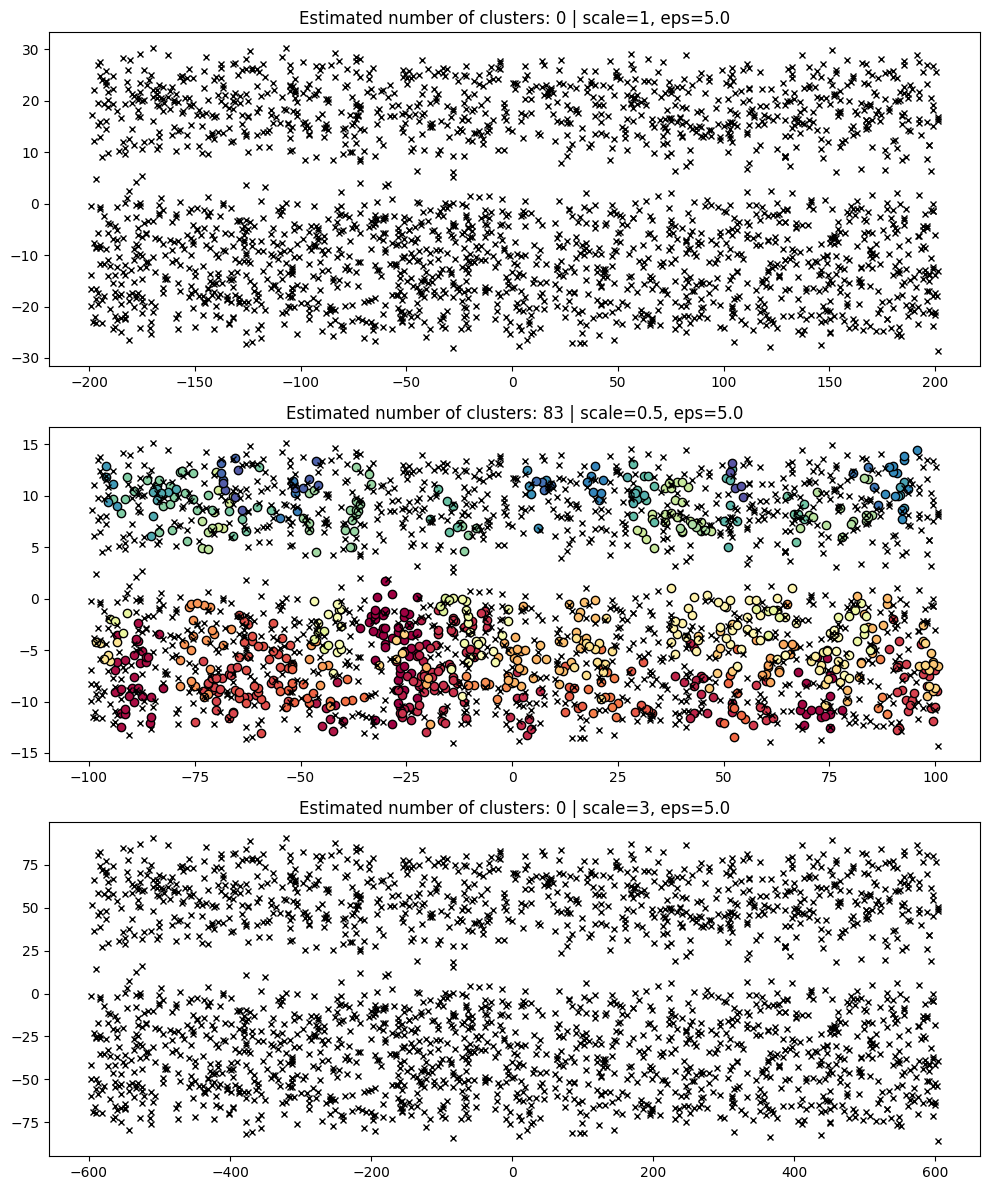

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=5.0)  # Skala epsilon disesuaikan dengan rentang data asli
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X_real * scale)
    # Proyeksi 2D khusus untuk kepentingan visualisasi
    X_scale_2d = pca.fit_transform(X_real * scale)
    plot(X_scale_2d, dbs.labels_, parameters={"scale": scale, "eps": 5.0}, ax=axes[idx])

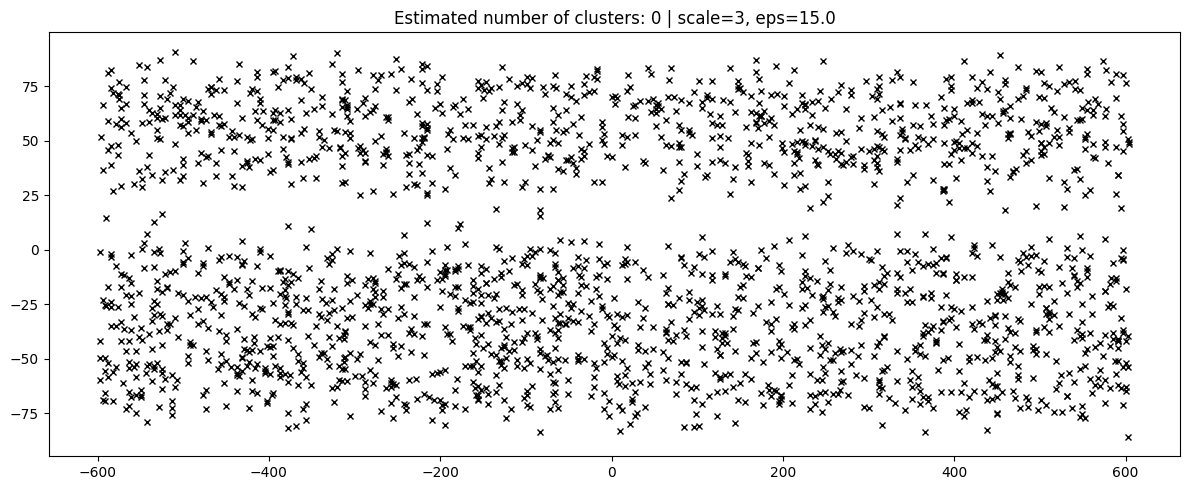

In [14]:
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=15.0).fit(3 * X_real)
X_scale3_2d = pca.fit_transform(3 * X_real)
plot(X_scale3_2d, dbs.labels_, parameters={"scale": 3, "eps": 15.0}, ax=axis)

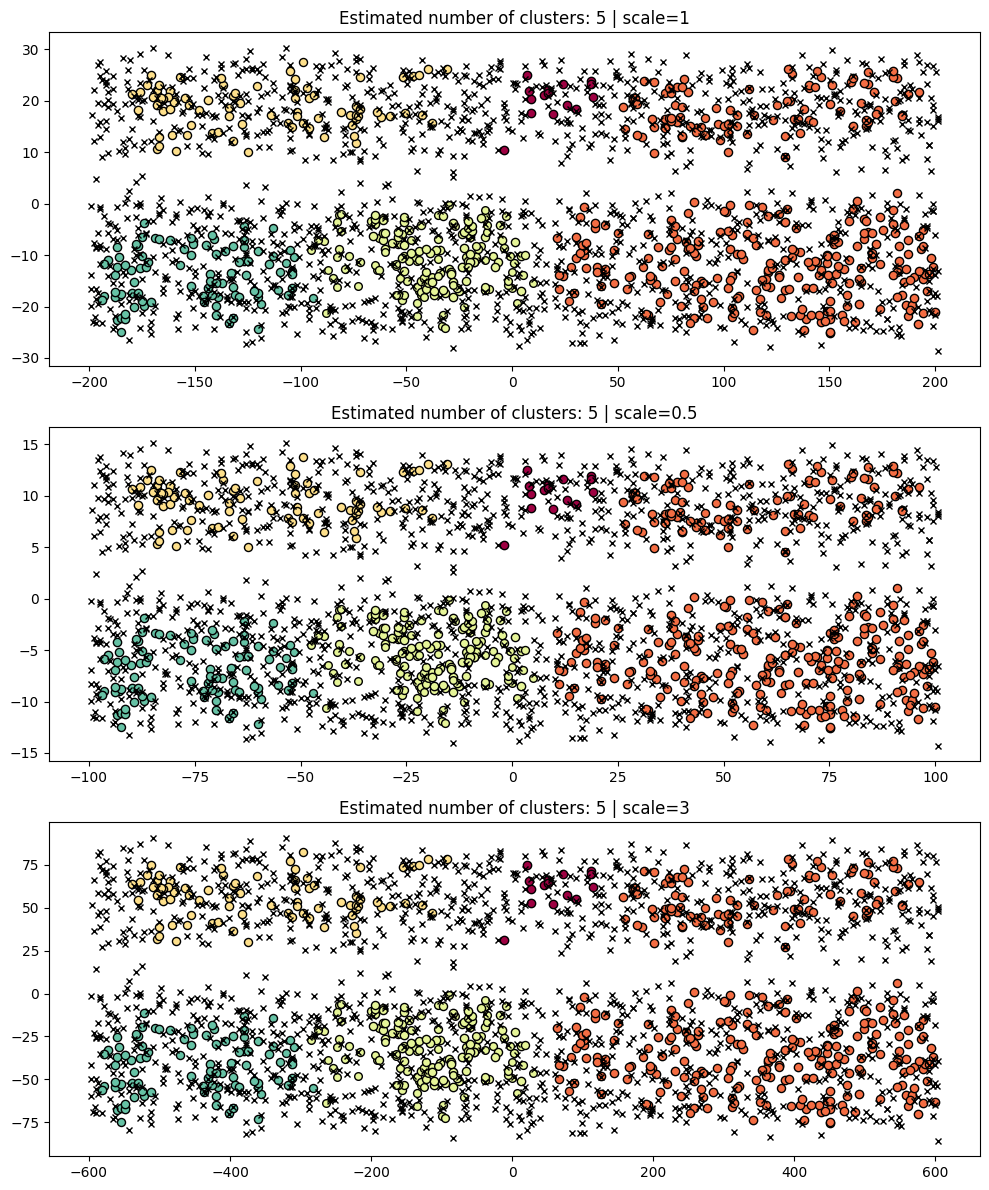

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN(min_cluster_size=15)
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X_real * scale)
    X_scale_2d = pca.fit_transform(X_real * scale)
    plot(X_scale_2d, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})

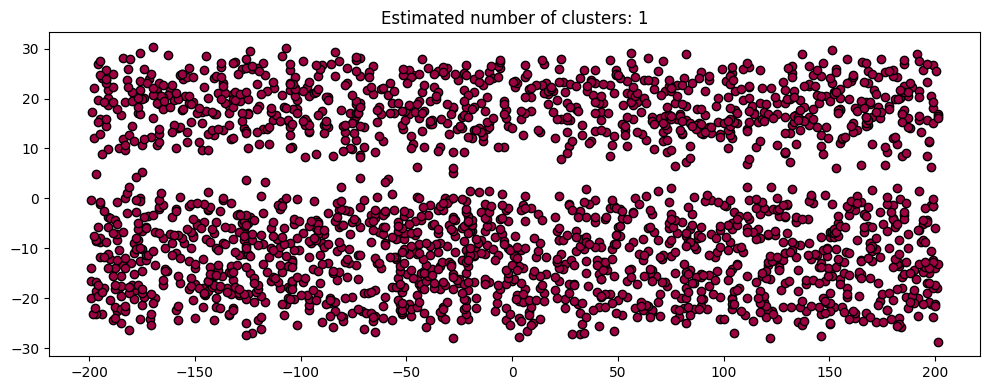

In [16]:
# Menggunakan data asli df yang telah diproyeksikan ke 2D
plot(X_real_2d, labels=None, ground_truth=False)

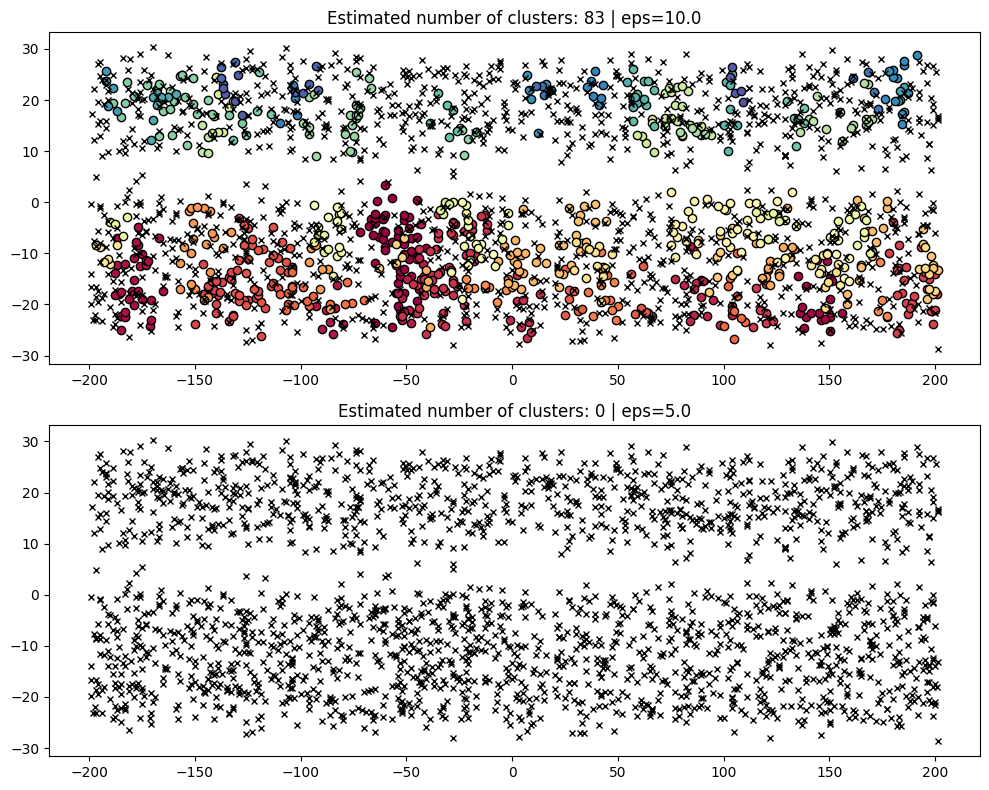

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 10.0}
dbs = DBSCAN(**params).fit(X_real)
plot(X_real_2d, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 5.0}
dbs = DBSCAN(**params).fit(X_real)
plot(X_real_2d, dbs.labels_, parameters=params, ax=axes[1])

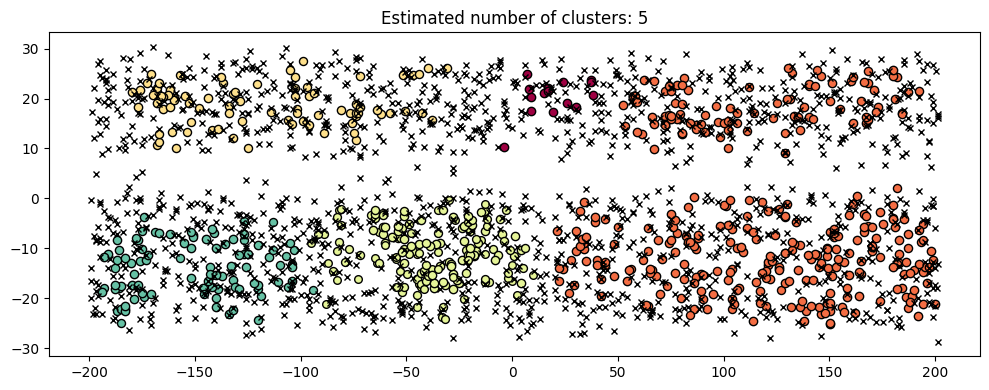

In [18]:
hdb = hdbscan.HDBSCAN(min_cluster_size=15).fit(X_real)
plot(X_real_2d, hdb.labels_, hdb.probabilities_)

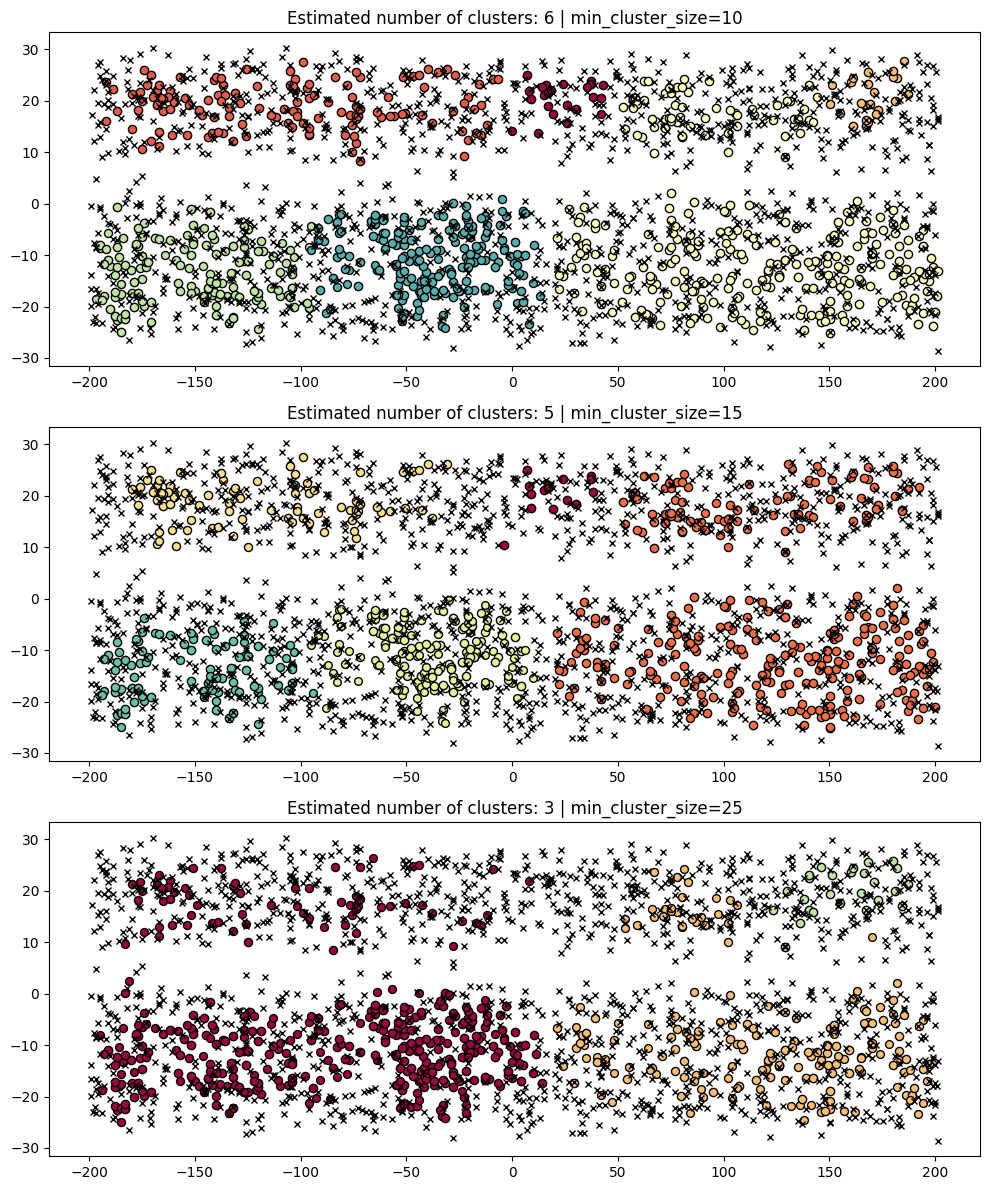

In [19]:
PARAM = ({"min_cluster_size": 10},  {"min_cluster_size": 15}, {"min_cluster_size": 25})
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X_real)
    plot(X_real_2d, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

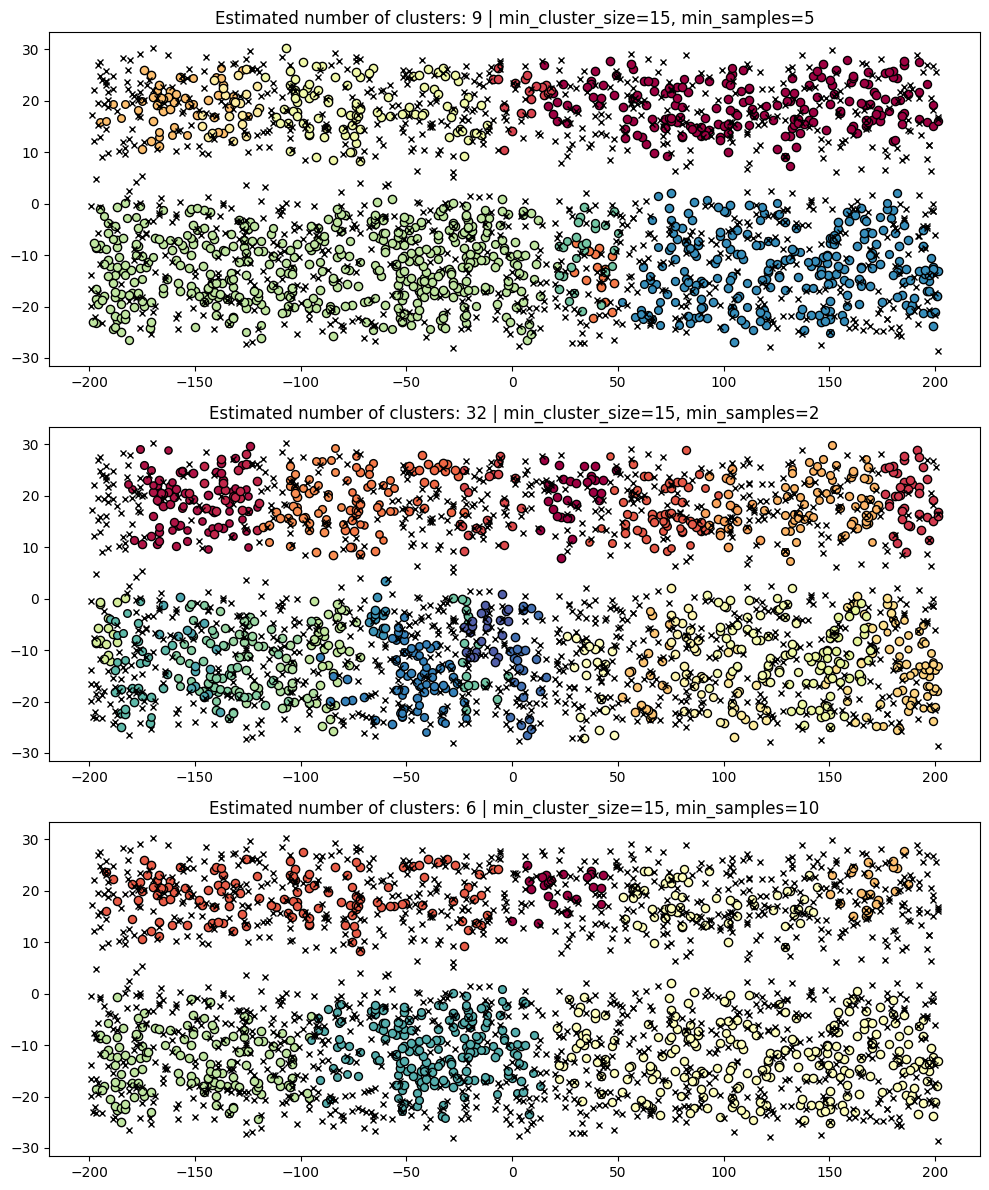

In [20]:
PARAM = (
    {"min_cluster_size": 15, "min_samples": 5},
    {"min_cluster_size": 15, "min_samples": 2},
    {"min_cluster_size": 15, "min_samples": 10},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X_real)
    plot(X_real_2d, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

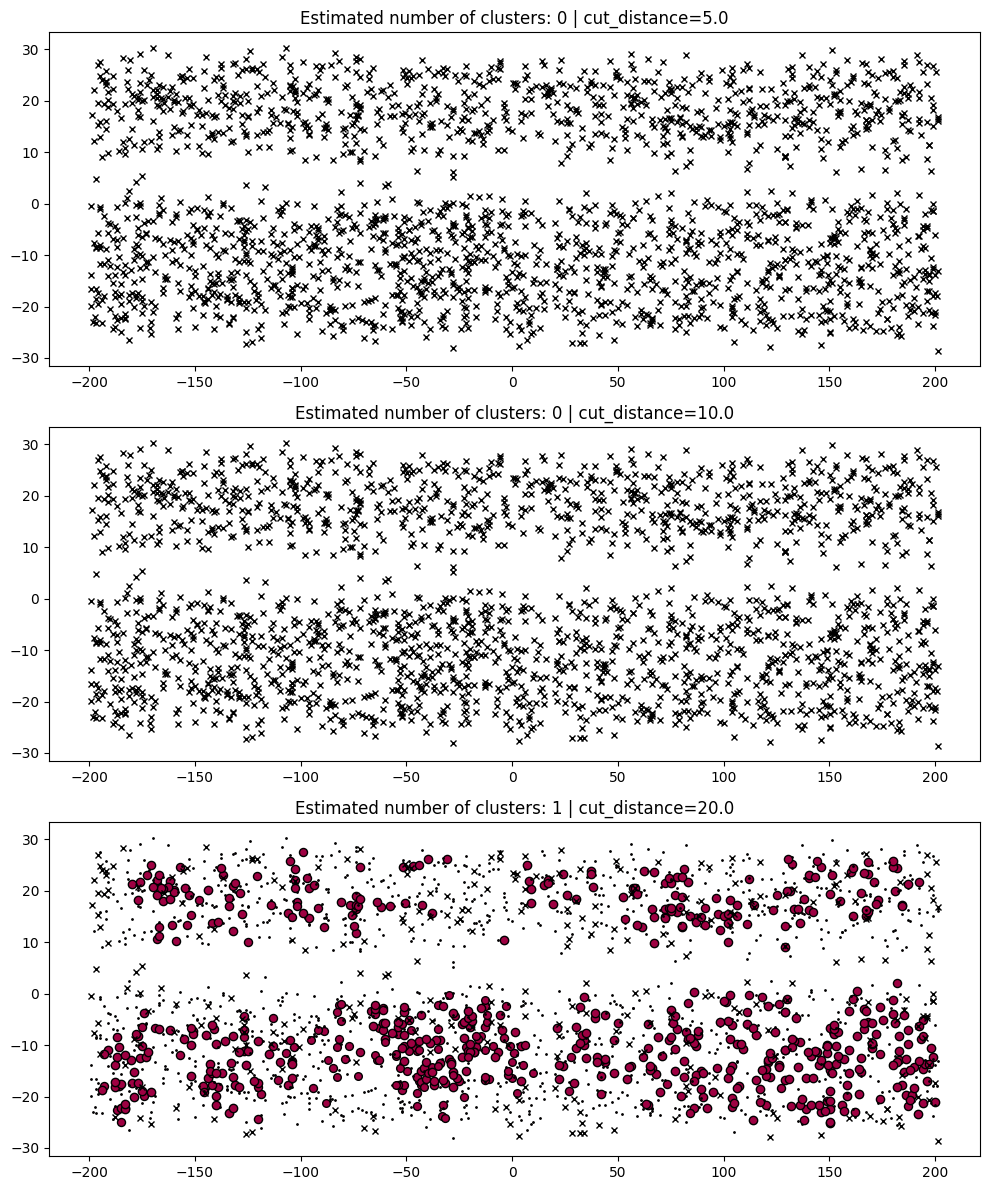

In [21]:
PARAM = (
    {"cut_distance": 5.0},
    {"cut_distance": 10.0},
    {"cut_distance": 20.0},
)
hdb = hdbscan.HDBSCAN(min_cluster_size=15).fit(X_real)
fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)
    plot(X_real_2d, labels, hdb.probabilities_, param, ax=axes[i])

In [22]:
from sklearn.metrics import silhouette_score

# Evaluasi silhouette score menggunakan data fitur asli X_real
sil_score = silhouette_score(X_real, hdb.labels_)
print(f"Silhouette Score on real df: {sil_score}")

Silhouette Score on real df: -0.35133121760941405


In [24]:
from sklearn.metrics import davies_bouldin_score

# Evaluasi Davies-Bouldin Index menggunakan data fitur asli X_real
dbi_score = davies_bouldin_score(X_real, hdb.labels_)
print(f"Davies-Bouldin Index on real df: {dbi_score}")

Davies-Bouldin Index on real df: 2.6074770016630238


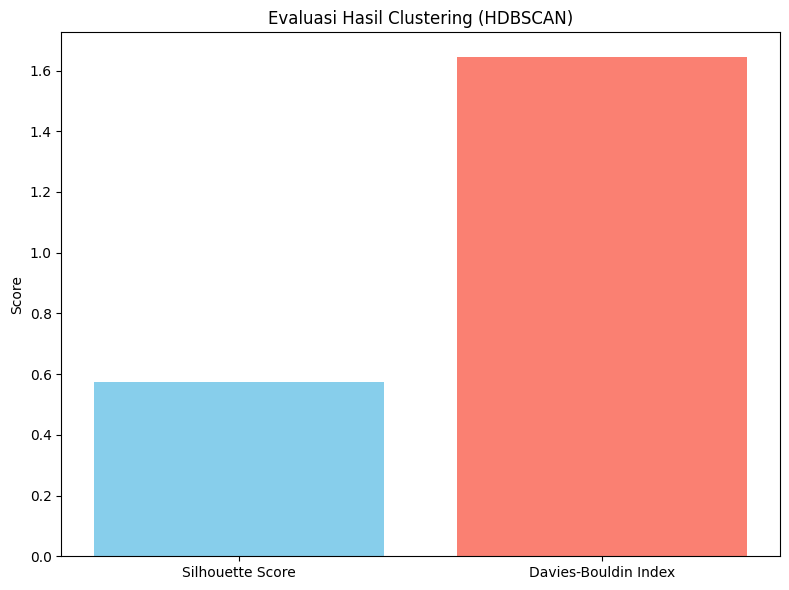

In [25]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import hdbscan

# Memastikan kita menggunakan data blob dengan 4 pusat cluster dari eksperimen HDBSCAN terakhir
centers_4 = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X_eval, labels_true_eval = make_blobs(
    n_samples=750, centers=centers_4, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)

# Melatih kembali HDBSCAN default pada data tersebut
hdb_eval = hdbscan.HDBSCAN().fit(X_eval)

sil_score = silhouette_score(X_eval, hdb_eval.labels_)
dbi_score = davies_bouldin_score(X_eval, hdb_eval.labels_)

scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

# Plot hasil evaluasi
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluasi Hasil Clustering (HDBSCAN)")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

# TUGAS

In [ ]:
# Instalasi pustaka hdbscan
!pip install hdbscan

# Import modul
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score
import hdbscan

# Memuat dataset Digits
digits = load_digits()
X = digits.data
y_true = digits.target
print(f"Dimensi dataset awal: {X.shape}")

In [ ]:
# Reduksi dimensi menggunakan t-SNE ke 2 dimensi
# (t-SNE sangat efektif untuk menangkap kelompok pada data citra/digits)
tsne = TSNE(n_components=2, random_state=42)
X_2d = tsne.fit_transform(X)

print("Reduksi dimensi menggunakan t-SNE selesai.")

In [ ]:
# Melakukan clustering menggunakan HDBSCAN pada data 2D
# min_cluster_size di-set ke 15 sebagai batas minimum anggota sebuah cluster
clusterer = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5)
cluster_labels = clusterer.fit_predict(X_2d)

# Menghitung metrik hasil cluster
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise = list(cluster_labels).count(-1)

print(f"Jumlah cluster yang terbentuk: {n_clusters}")
print(f"Banyaknya noise (outlier): {n_noise} dari total {len(X)} data")

In [ ]:
# Visualisasi hasil clustering HDBSCAN
plt.figure(figsize=(10, 7))

# Memisahkan data noise (label -1) dan data yang berhasil di-cluster
noise_mask = cluster_labels == -1
clustered_mask = cluster_labels != -1

# Plot Noise (warna abu-abu, bentuk 'x')
plt.scatter(X_2d[noise_mask, 0], X_2d[noise_mask, 1],
            c='lightgray', marker='x', label='Noise', alpha=0.7, s=20)

# Plot Cluster
scatter = plt.scatter(X_2d[clustered_mask, 0], X_2d[clustered_mask, 1],
                      c=cluster_labels[clustered_mask], cmap='tab20', s=30, alpha=0.9)

plt.colorbar(scatter, label='Cluster Label (HDBSCAN)')
plt.title('Visualisasi HDBSCAN pada Digits Dataset (via t-SNE 2D)', fontsize=14)
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Mengukur kesesuaian cluster dengan label aslinya menggunakan ARI
ari_score = adjusted_rand_score(y_true, cluster_labels)
print(f"Adjusted Rand Index (ARI) Score: {ari_score:.4f}")